# NLP Assignment 5 — Text Summarization with NLTK

Four summarization approaches — **Extractive**, **Abstractive**, **Generic** and **Query-based** — built and compared on one English and one Hindi news article from public corpora.

| Part | Corpus | Reference summary | Abstractive model |
|---|---|---|---|
| C — English | CNN/DailyMail (test split) | Journalist highlights, 3–4 sentences | T5-small |
| D — Hindi | XL-Sum Hindi (BBC, test split) | Journalist summary, 1 sentence | mT5 (XL-Sum) |

Three tunable parameters: summary ratio, number of sentences, frequency weight. Evaluation: ROUGE-1/2/L, compression ratio, content coverage.

---
## Part C — English: Extractive, Abstractive (T5), Generic and Query-based

### C1. Setup: install, imports, NLTK resources, objective

In [1]:
# ---- 1. Install Required Packages ----
import sys
import subprocess

subprocess.check_call(
    [sys.executable, "-m", "pip", "install", "-q", "rouge-score", "transformers", "sentencepiece"]
)

# ---- 2. Import Libraries ----
import re
import math
import random
import warnings

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from rouge_score import rouge_scorer

from transformers import T5Tokenizer, T5ForConditionalGeneration

from IPython.display import display

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid")

print("=" * 80)
print("LIBRARIES LOADED")
print("=" * 80)

# ---- 3. Download Nltk Resources ----
print("\nDownloading NLTK resources...")

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

print("NLTK resources downloaded successfully.")

# ---- 4. Title And Objective ----
print("\n" + "=" * 80)
print("NLP TEXT SUMMARIZATION PROJECT")
print("=" * 80)

print("""
OBJECTIVE
---------
Build and compare four types of text summarization:

1. Extractive Summarization
2. Abstractive Summarization
3. Generic Summarization
4. Query-Based Summarization

The project uses one news article from the CNN/DailyMail corpus,
with the journalist-written highlights as the reference summary.

Evaluation metrics:
- ROUGE-1
- ROUGE-2
- ROUGE-L
- Compression Ratio
- Content Coverage

Three tunable parameters:
- Summary Ratio
- Number of Sentences
- Frequency Weight
""")

LIBRARIES LOADED

NLTK resources downloaded successfully.

NLP TEXT SUMMARIZATION PROJECT

OBJECTIVE
---------
Build and compare four types of text summarization:

1. Extractive Summarization
2. Abstractive Summarization
3. Generic Summarization
4. Query-Based Summarization

The project uses one news article from the CNN/DailyMail corpus,
with the journalist-written highlights as the reference summary.

Evaluation metrics:
- ROUGE-1
- ROUGE-2
- ROUGE-L
- Compression Ratio
- Content Coverage

Three tunable parameters:
- Summary Ratio
- Number of Sentences
- Frequency Weight



### C2. Data: dummy document and reference summary

In [2]:
# ---- 5. Load a CNN/DailyMail article (public corpus) ----
# CNN/DailyMail (Hermann et al., 2015; See et al., 2017) is the standard English news summarization benchmark:
# ~300k articles, each paired with the journalist-written "highlights" (3-4 bullet sentences) used as the reference.
from datasets import load_dataset

CNNDM_INDEX = 0   # change to try another article
cnndm = load_dataset("abisee/cnn_dailymail", "3.0.0", split="test")
print(f"CNN/DailyMail test split: {len(cnndm)} articles")
sample = cnndm[CNNDM_INDEX]

document = sample["article"]
document = re.sub(r"^.*?\(CNN\)\s*--\s*", "", document, count=1)   # strip the dateline if present
document = re.sub(r"\s+", " ", document).strip()

# ---- 6. Reference summary (journalist highlights) ----
reference_summary = re.sub(r"\s+", " ", sample["highlights"]).strip()

print("\n--- Article (first 800 characters) ---\n" + document[:800] + " ...")
print("\n--- Reference summary (highlights) ---\n" + reference_summary)
print("\nOriginal document words:", len(word_tokenize(document)))
print("Reference summary words:", len(word_tokenize(reference_summary)))

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

3.0.0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  259MB            

... (5 outputs left out)

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

CNN/DailyMail test split: 11490 articles

--- Article (first 800 characters) ---
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014." Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis. As members of the court, Palestinians may be subject to counter-charges as well. I ...

--- Reference summary (highlights) ---
Membership gives the ICC jurisdiction over alleged crimes committed in Pal

### C3. Preprocessing and tunable parameters

In [3]:
# ---- 7. Nltk Preprocessing ----
print("\n" + "=" * 80)
print("ORIGINAL DOCUMENT")
print("=" * 80)
print(document.strip())

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_words(text):
    """
    NLTK preprocessing:
    1. Lowercase
    2. Word tokenization
    3. Punctuation removal
    4. Stopword removal
    5. Lemmatization
    """
    tokens = word_tokenize(text.lower())
    clean_words = []
    for token in tokens:
        if not token.isalpha():
            continue
        if token in stop_words:
            continue
        token = lemmatizer.lemmatize(token)
        clean_words.append(token)
    return clean_words

def get_sentences(text):
    return sent_tokenize(text)

def word_count(text):
    """
    Consistent word-count function used throughout the project.
    """
    return len([word for word in word_tokenize(text) if word.isalpha()])

def get_word_frequencies(text):
    words = preprocess_words(text)
    frequencies = Counter(words)
    if not frequencies:
        return {}
    maximum = max(frequencies.values())
    return {word: count / maximum for word, count in frequencies.items()}

print("\n" + "=" * 80)
print("PREPROCESSING")
print("=" * 80)

print("Number of sentences:", len(get_sentences(document)))

print("Number of meaningful words:", len(preprocess_words(document)))

print("\nTop 20 meaningful words:")

print(Counter(preprocess_words(document)).most_common(20))

# ---- 8. Three Tunable Parameters ----
summary_ratio = 0.20
num_sentences = 5
frequency_weight = 0.70

print("\n" + "=" * 80)
print("THREE TUNABLE PARAMETERS")
print("=" * 80)

print("1. Summary Ratio =", summary_ratio)
print("2. Number of Sentences =", num_sentences)
print("3. Frequency Weight =", frequency_weight)

print("""
Summary Ratio:
Controls the target percentage of the document retained.

Number of Sentences:
Controls the maximum number of sentences.

Frequency Weight:
Controls the balance between word frequency and sentence position
inside the Generic summarizer.

Position Weight = 1 - Frequency Weight
""")

# ---- 9. Determine Summary Length ----
def calculate_target_sentences(text, summary_ratio, num_sentences):
    """
    Summary Ratio determines the target length.
    Number of Sentences acts as an upper limit.
    This allows both parameters to have meaningful effects.
    """
    sentences = sent_tokenize(text)
    if not sentences:
        return 0
    ratio_target = max(1, round(len(sentences) * summary_ratio))
    target = min(ratio_target, num_sentences, len(sentences))
    return max(1, target)

def select_top_sentences(sentences, scores, number_to_select):
    if not sentences:
        return ""
    ranked_indices = sorted(range(len(sentences)), key=lambda i: (-scores[i], i))
    selected_indices = sorted(ranked_indices[:number_to_select])
    return " ".join(sentences[i] for i in selected_indices)


ORIGINAL DOCUMENT
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014." Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis. As members of the court, Palestinians may be subject to counter-charges as well. Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join the body. But Palestinian Foreign Minister Riad al-Malki, speaking at Wedne

### C4. Extractive, Generic and Query-based summarizers

In [4]:
# ---- 10. Extractive Summarizer ----
def extractive_summarizer(text, summary_ratio=0.20, num_sentences=5):
    sentences = sent_tokenize(text)
    if not sentences:
        return ""
    target = calculate_target_sentences(text, summary_ratio, num_sentences)
    frequencies = get_word_frequencies(text)
    scores = []
    for sentence in sentences:
        words = preprocess_words(sentence)
        if not words:
            scores.append(0)
            continue
        score = sum(frequencies.get(word, 0) for word in words)
        score /= len(words)
        scores.append(score)
    return select_top_sentences(sentences, scores, target)

# ---- 11. Generic Summarizer ----
def generic_summarizer(text, summary_ratio=0.20, num_sentences=5, frequency_weight=0.70):
    """
    Generic summarization.
    It does NOT use a query.
    It combines:
    - word frequency
    - sentence position
    - sentence content/length
    Frequency Weight is configurable.
    """
    sentences = sent_tokenize(text)
    if not sentences:
        return ""
    target = calculate_target_sentences(text, summary_ratio, num_sentences)
    frequencies = get_word_frequencies(text)
    position_weight = 1 - frequency_weight
    scores = []
    total_sentences = len(sentences)
    for index, sentence in enumerate(sentences):
        words = preprocess_words(sentence)
        if words:
            frequency_score = sum(frequencies.get(word, 0) for word in words) / len(words)
        else:
            frequency_score = 0
        # Beginning sentences receive slightly higher scores.
        position_score = (total_sentences - index) / total_sentences
        # Content/length normalization.
        if words:
            length_score = min(len(words) / 20, 1.0)
        else:
            length_score = 0
        final_score = (
            frequency_weight * frequency_score + position_weight * position_score + 0.10 * length_score
        )
        scores.append(final_score)
    return select_top_sentences(sentences, scores, target)

# ---- 12. Query-Based Summarizer ----
def query_based_summarizer(text, query, summary_ratio=0.20, num_sentences=5):
    sentences = sent_tokenize(text)
    if not sentences:
        return ""
    target = calculate_target_sentences(text, summary_ratio, num_sentences)
    documents = [query] + sentences
    vectorizer = TfidfVectorizer(stop_words="english")
    matrix = vectorizer.fit_transform(documents)
    query_vector = matrix[0]
    sentence_vectors = matrix[1:]
    similarities = cosine_similarity(query_vector, sentence_vectors).flatten()
    frequencies = get_word_frequencies(text)
    scores = []
    for index, sentence in enumerate(sentences):
        words = preprocess_words(sentence)
        if words:
            frequency_score = sum(frequencies.get(word, 0) for word in words) / len(words)
        else:
            frequency_score = 0
        final_score = 0.80 * similarities[index] + 0.20 * frequency_score
        scores.append(final_score)
    return select_top_sentences(sentences, scores, target)

### C5. Abstractive summarizer (T5-small)

In [5]:
# ---- 13. Load T5 For Abstractive Summarization ----
print("\n" + "=" * 80)
print("LOADING T5 ABSTRACTIVE MODEL")
print("=" * 80)

model_name = "t5-small"

tokenizer = T5Tokenizer.from_pretrained(model_name)

model = T5ForConditionalGeneration.from_pretrained(model_name)

print("T5-small loaded successfully.")

# ---- 14. T5 Chunking Function ----
def split_into_chunks(text, max_words=250):
    """
    Splits a document into manageable word chunks.
    This prevents the abstractive model from only seeing
    the first part of a long document.
    """
    words = text.split()
    chunks = []
    for i in range(0, len(words), max_words):
        chunks.append(" ".join(words[i : i + max_words]))
    return chunks

def generate_t5_summary(text, max_length=100, min_length=30):
    input_text = "summarize: " + text
    inputs = tokenizer(input_text, return_tensors="pt", max_length=512, truncation=True)
    output = model.generate(
        **inputs,
        max_length=max_length,
        min_length=min(min_length, max_length - 1),
        num_beams=4,
        length_penalty=1.0,
        no_repeat_ngram_size=3,
        early_stopping=True
    )
    return tokenizer.decode(output[0], skip_special_tokens=True)

# ---- 15. Abstractive Summarizer ----
def abstractive_summarizer(text, summary_ratio=0.20, num_sentences=5):
    """
    Abstractive summarization using T5.
    The document is divided into chunks.
    Each chunk is summarized.
    The intermediate summaries are then combined
    and summarized again.
    """
    chunks = split_into_chunks(text, max_words=250)
    intermediate_summaries = []
    for chunk in chunks:
        chunk_summary = generate_t5_summary(chunk, max_length=80, min_length=20)
        if chunk_summary.strip():
            intermediate_summaries.append(chunk_summary)
    if not intermediate_summaries:
        return ""
    combined = " ".join(intermediate_summaries)
    final_word_target = max(40, min(130, int(word_count(text) * summary_ratio)))
    # If combined text is already short,
    # use it directly.
    if word_count(combined) <= final_word_target:
        return combined
    final_summary = generate_t5_summary(
        combined, max_length=final_word_target, min_length=max(20, min(50, final_word_target // 2))
    )
    return final_summary


LOADING T5 ABSTRACTIVE MODEL


tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5-small loaded successfully.


### C6. Generate and display the four summaries

In [6]:
# ---- 16. Query ----
# The query is built from the article's most frequent content words, so it stays valid for any article index.
_top = [w for w, _ in Counter(preprocess_words(document)).most_common(6)]
query = "What does the article say about " + ", ".join(_top) + "?"
print("Query:", query)
# ---- 17. Generate Four Summaries ----
print("\n" + "=" * 80)
print("GENERATING FOUR SUMMARIES")
print("=" * 80)

summaries = {}

# ------------------------------------------------
# 1. Extractive
# ------------------------------------------------

summaries["Extractive"] = extractive_summarizer(document, summary_ratio, num_sentences)

# ------------------------------------------------
# 2. Abstractive
# ------------------------------------------------

print("\nGenerating abstractive summary...")

summaries["Abstractive"] = abstractive_summarizer(document, summary_ratio, num_sentences)

# ------------------------------------------------
# 3. Generic
# ------------------------------------------------

summaries["Generic"] = generic_summarizer(document, summary_ratio, num_sentences, frequency_weight)

# ------------------------------------------------
# 4. Query-Based
# ------------------------------------------------

summaries["Query-Based"] = query_based_summarizer(document, query, summary_ratio, num_sentences)

# ---- 18. Display Summaries ----
for method, summary in summaries.items():

    print("\n" + "=" * 80)
    print(method.upper() + " SUMMARY")
    print("=" * 80)
    if method == "Query-Based":
        print("Query:", query)
        print()
    print(summary)
    print("\nSentence count:", len(sent_tokenize(summary)))
    print("Word count:", word_count(summary))

Query: What does the article say about icc, said, palestinian, court, state, palestine?

GENERATING FOUR SUMMARIES

Generating abstractive summary...

EXTRACTIVE SUMMARY
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. As members of the court, Palestinians may be subject to counter-charges as well. Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join the body. The United States also said it "strongly" disagreed with the court's decision. "As we have said repeatedly, we do not believe that Palestine is a state and therefore we do not believe that it is eligible to join the ICC," the State Department said in a statement.

Sentence count: 5
Word count: 107

ABSTRACTIVE SUMMARY
the Palestinian Authority officially became the 123rd member of the international criminal court. the forma

### C7. Evaluation: statistics, ROUGE, content coverage, final table

In [7]:
# ---- 19. Summary Statistics ----
def compression_ratio(summary, original):
    original_words = word_count(original)
    if original_words == 0:
        return 0
    return word_count(summary) / original_words

statistics = []

for method, summary in summaries.items():

    statistics.append(
        {
            "Method": method,
            "Sentences": len(sent_tokenize(summary)),
            "Words": word_count(summary),
            "Compression Ratio": compression_ratio(summary, document),
        }
    )

summary_stats_df = pd.DataFrame(statistics)

print("\n" + "=" * 80)
print("SUMMARY STATISTICS")
print("=" * 80)

display(summary_stats_df.style.format({"Compression Ratio": "{:.3f}"}))

# ---- 20. Rouge Evaluation ----
rouge_scorer_object = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def evaluate_rouge(summary, reference):
    scores = rouge_scorer_object.score(reference, summary)
    return {
        "ROUGE-1 Precision": scores["rouge1"].precision,
        "ROUGE-1 Recall": scores["rouge1"].recall,
        "ROUGE-1 F1": scores["rouge1"].fmeasure,
        "ROUGE-2 Precision": scores["rouge2"].precision,
        "ROUGE-2 Recall": scores["rouge2"].recall,
        "ROUGE-2 F1": scores["rouge2"].fmeasure,
        "ROUGE-L Precision": scores["rougeL"].precision,
        "ROUGE-L Recall": scores["rougeL"].recall,
        "ROUGE-L F1": scores["rougeL"].fmeasure,
    }

rouge_results = []

for method, summary in summaries.items():

    scores = evaluate_rouge(summary, reference_summary)
    rouge_results.append({"Method": method, **scores})

rouge_df = pd.DataFrame(rouge_results)

print("\n" + "=" * 80)
print("ROUGE EVALUATION")
print("=" * 80)

display(rouge_df.style.format({column: "{:.3f}" for column in rouge_df.columns if column != "Method"}))

# ---- 21. Content Coverage ----
def content_coverage(summary, reference, threshold=0.15):
    """
    Content Coverage:
    1. Split reference summary into sentences.
    2. Split generated summary into sentences.
    3. Convert sentences to TF-IDF vectors.
    4. Calculate cosine similarity.
    5. For each reference sentence, find its best matching
       generated sentence.
    6. A reference sentence is considered covered if its
       similarity is >= threshold.
    Coverage =
        covered reference sentences /
        total reference sentences
    """
    reference_sentences = sent_tokenize(reference)
    summary_sentences = sent_tokenize(summary)
    if not reference_sentences:
        return 0
    if not summary_sentences:
        return 0
    combined = reference_sentences + summary_sentences
    vectorizer = TfidfVectorizer(stop_words="english")
    try:
        matrix = vectorizer.fit_transform(combined)
    except ValueError:
        return 0
    reference_matrix = matrix[: len(reference_sentences)]
    summary_matrix = matrix[len(reference_sentences) :]
    similarities = cosine_similarity(reference_matrix, summary_matrix)
    best_similarity = similarities.max(axis=1)
    covered = np.sum(best_similarity >= threshold)
    return covered / len(reference_sentences)

coverage_results = []

for method, summary in summaries.items():

    coverage_results.append(
        {
            "Method": method,
            "Content Coverage": content_coverage(summary, reference_summary),
            "Compression Ratio": compression_ratio(summary, document),
        }
    )

coverage_df = pd.DataFrame(coverage_results)

print("\n" + "=" * 80)
print("ADDITIONAL EVALUATION METRICS")
print("=" * 80)

display(coverage_df.style.format({"Content Coverage": "{:.3f}", "Compression Ratio": "{:.3f}"}))

# ---- 22. Final Performance Table ----
final_df = rouge_df[["Method", "ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1"]].merge(coverage_df, on="Method")

final_df["Overall Score"] = final_df[["ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1"]].mean(axis=1)

final_df = final_df.sort_values("Overall Score", ascending=False).reset_index(drop=True)

print("\n" + "=" * 80)
print("FINAL CONSOLIDATED RESULTS")
print("=" * 80)

display(
    final_df.style.format(
        {
            "ROUGE-1 F1": "{:.3f}",
            "ROUGE-2 F1": "{:.3f}",
            "ROUGE-L F1": "{:.3f}",
            "Content Coverage": "{:.3f}",
            "Compression Ratio": "{:.3f}",
            "Overall Score": "{:.3f}",
        }
    )
)


SUMMARY STATISTICS


,Method,Sentences,Words,Compression Ratio
0,Extractive,5,107,0.191
1,Abstractive,8,103,0.184
2,Generic,5,115,0.205
3,Query-Based,5,153,0.273



ROUGE EVALUATION


,Method,ROUGE-1 Precision,ROUGE-1 Recall,ROUGE-1 F1,ROUGE-2 Precision,ROUGE-2 Recall,ROUGE-2 F1,ROUGE-L Precision,ROUGE-L Recall,ROUGE-L F1
0,Extractive,0.180,0.588,0.276,0.109,0.364,0.168,0.162,0.529,0.248
1,Abstractive,0.196,0.618,0.298,0.085,0.273,0.129,0.103,0.324,0.156
2,Generic,0.240,0.853,0.374,0.150,0.545,0.235,0.174,0.618,0.271
3,Query-Based,0.104,0.471,0.170,0.046,0.212,0.075,0.097,0.441,0.160



ADDITIONAL EVALUATION METRICS


,Method,Content Coverage,Compression Ratio
0,Extractive,1.000,0.191
1,Abstractive,1.000,0.184
2,Generic,1.000,0.205
3,Query-Based,0.500,0.273



FINAL CONSOLIDATED RESULTS


,Method,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1,Content Coverage,Compression Ratio,Overall Score
0,Generic,0.374,0.235,0.271,1.000,0.205,0.293
1,Extractive,0.276,0.168,0.248,1.000,0.191,0.231
2,Abstractive,0.298,0.129,0.156,1.000,0.184,0.194
3,Query-Based,0.170,0.075,0.160,0.500,0.273,0.135


### C8. Parameter tuning (all four methods)

In [8]:
# ---- 23. Parameter Tuning ----
summary_ratios = [0.10, 0.20, 0.30]

sentence_values = [3, 5, 8]

frequency_weights = [0.30, 0.50, 0.70]

print("\n" + "=" * 80)
print("PARAMETER TUNING EXPERIMENT")
print("=" * 80)

print("Summary ratios:", summary_ratios)

print("Sentence values:", sentence_values)

print("Frequency weights:", frequency_weights)

tuning_results = []

# ---- 24. Tuning: Extractive ----
for ratio in summary_ratios:

    for sentence_limit in sentence_values:
        summary = extractive_summarizer(document, ratio, sentence_limit)
        scores = evaluate_rouge(summary, reference_summary)
        tuning_results.append(
            {
                "Method": "Extractive",
                "Summary Ratio": ratio,
                "Number of Sentences": sentence_limit,
                "Frequency Weight": np.nan,
                "ROUGE-1": scores["ROUGE-1 F1"],
                "ROUGE-2": scores["ROUGE-2 F1"],
                "ROUGE-L": scores["ROUGE-L F1"],
                "Compression Ratio": compression_ratio(summary, document),
            }
        )

# ---- 25. Tuning: Generic ----
for ratio in summary_ratios:

    for sentence_limit in sentence_values:
        for weight in frequency_weights:
            summary = generic_summarizer(document, ratio, sentence_limit, weight)
            scores = evaluate_rouge(summary, reference_summary)
            tuning_results.append(
                {
                    "Method": "Generic",
                    "Summary Ratio": ratio,
                    "Number of Sentences": sentence_limit,
                    "Frequency Weight": weight,
                    "ROUGE-1": scores["ROUGE-1 F1"],
                    "ROUGE-2": scores["ROUGE-2 F1"],
                    "ROUGE-L": scores["ROUGE-L F1"],
                    "Compression Ratio": compression_ratio(summary, document),
                }
            )

# ---- 26. Tuning: Query-Based ----
for ratio in summary_ratios:

    for sentence_limit in sentence_values:
        summary = query_based_summarizer(document, query, ratio, sentence_limit)
        scores = evaluate_rouge(summary, reference_summary)
        tuning_results.append(
            {
                "Method": "Query-Based",
                "Summary Ratio": ratio,
                "Number of Sentences": sentence_limit,
                "Frequency Weight": np.nan,
                "ROUGE-1": scores["ROUGE-1 F1"],
                "ROUGE-2": scores["ROUGE-2 F1"],
                "ROUGE-L": scores["ROUGE-L F1"],
                "Compression Ratio": compression_ratio(summary, document),
            }
        )

# ---- 27. Tuning: Abstractive ----
#
# To keep the experiment manageable, abstractive tuning tests
# summary ratio and sentence limit combinations without repeatedly
# downloading/reloading the model.

print("\nRunning abstractive tuning...")

for ratio in summary_ratios:

    for sentence_limit in sentence_values:
        summary = abstractive_summarizer(document, ratio, sentence_limit)
        scores = evaluate_rouge(summary, reference_summary)
        tuning_results.append(
            {
                "Method": "Abstractive",
                "Summary Ratio": ratio,
                "Number of Sentences": sentence_limit,
                "Frequency Weight": np.nan,
                "ROUGE-1": scores["ROUGE-1 F1"],
                "ROUGE-2": scores["ROUGE-2 F1"],
                "ROUGE-L": scores["ROUGE-L F1"],
                "Compression Ratio": compression_ratio(summary, document),
            }
        )

# ---- 28. Create Tuning Dataframe ----
tuning_df = pd.DataFrame(tuning_results)

tuning_df["Overall Score"] = tuning_df[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean(axis=1)

print("\n" + "=" * 80)
print("TUNING RESULTS")
print("=" * 80)

display(
    tuning_df.head(30).style.format(
        {
            "Summary Ratio": "{:.2f}",
            "Frequency Weight": lambda x: "-" if pd.isna(x) else f"{x:.2f}",
            "ROUGE-1": "{:.3f}",
            "ROUGE-2": "{:.3f}",
            "ROUGE-L": "{:.3f}",
            "Compression Ratio": "{:.3f}",
            "Overall Score": "{:.3f}",
        }
    )
)

# ---- 29. Best Tuning Configuration ----
best_tuning = tuning_df.loc[tuning_df["Overall Score"].idxmax()]

print("\n" + "=" * 80)
print("BEST TUNING CONFIGURATION")
print("=" * 80)

print("Method:", best_tuning["Method"])

print("Summary Ratio:", best_tuning["Summary Ratio"])

print("Number of Sentences:", int(best_tuning["Number of Sentences"]))

if pd.isna(best_tuning["Frequency Weight"]):

    print("Frequency Weight: Not applicable")

else:

    print("Frequency Weight:", best_tuning["Frequency Weight"])

print("ROUGE-1:", round(best_tuning["ROUGE-1"], 4))

print("ROUGE-2:", round(best_tuning["ROUGE-2"], 4))

print("ROUGE-L:", round(best_tuning["ROUGE-L"], 4))

print("Overall Score:", round(best_tuning["Overall Score"], 4))


PARAMETER TUNING EXPERIMENT
Summary ratios: [0.1, 0.2, 0.3]
Sentence values: [3, 5, 8]
Frequency weights: [0.3, 0.5, 0.7]

Running abstractive tuning...

TUNING RESULTS


,Method,Summary Ratio,Number of Sentences,Frequency Weight,ROUGE-1,ROUGE-2,ROUGE-L,Compression Ratio,Overall Score
0,Extractive,0.10,3,-,0.229,0.064,0.146,0.105,0.146
1,Extractive,0.10,5,-,0.229,0.064,0.146,0.105,0.146
2,Extractive,0.10,8,-,0.229,0.064,0.146,0.105,0.146
3,Extractive,0.20,3,-,0.229,0.064,0.146,0.105,0.146
4,Extractive,0.20,5,-,0.276,0.168,0.248,0.191,0.231
5,Extractive,0.20,8,-,0.276,0.168,0.248,0.191,0.231
6,Extractive,0.30,3,-,0.229,0.064,0.146,0.105,0.146
7,Extractive,0.30,5,-,0.276,0.168,0.248,0.191,0.231
8,Extractive,0.30,8,-,0.181,0.110,0.163,0.326,0.151
9,Generic,0.10,3,0.30,0.364,0.218,0.347,0.148,0.310



BEST TUNING CONFIGURATION
Method: Generic
Summary Ratio: 0.1
Number of Sentences: 3
Frequency Weight: 0.3
ROUGE-1: 0.3636
ROUGE-2: 0.2185
ROUGE-L: 0.3471
Overall Score: 0.3097


### C9. Visualisations

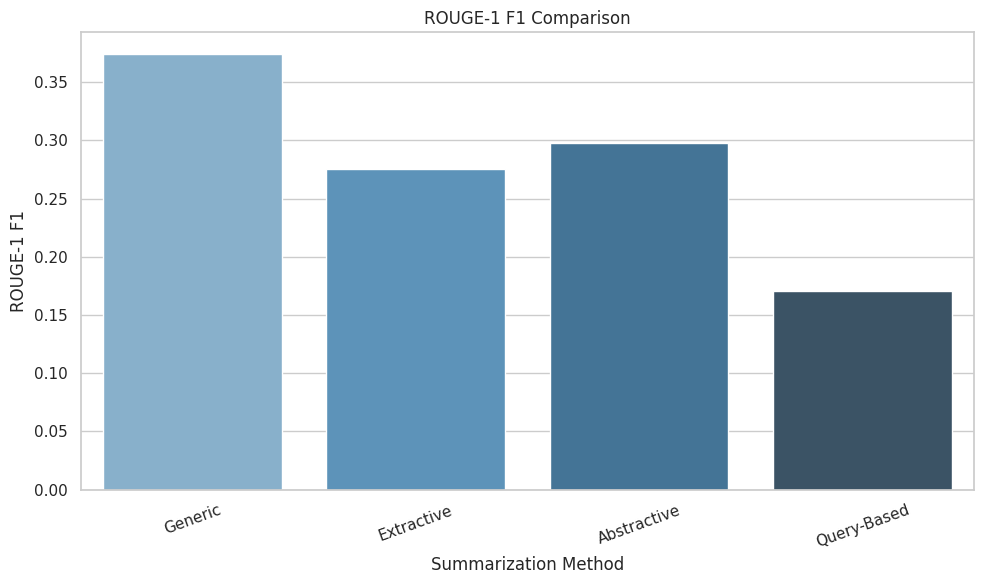

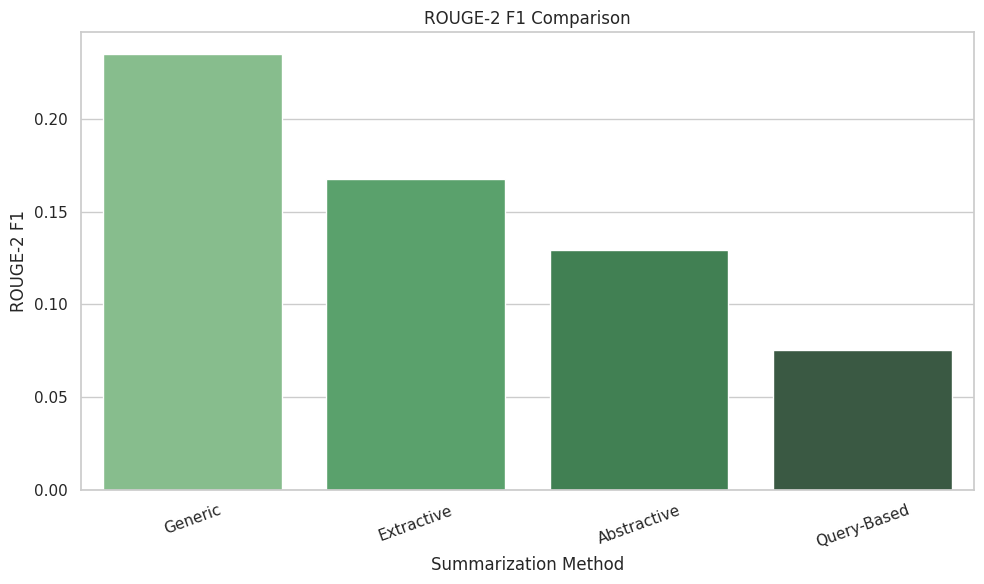

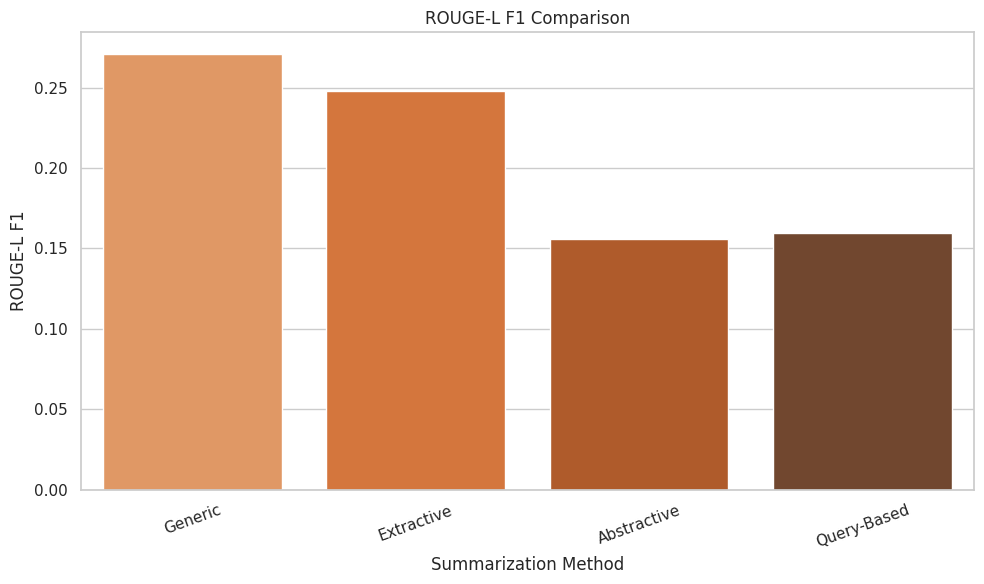

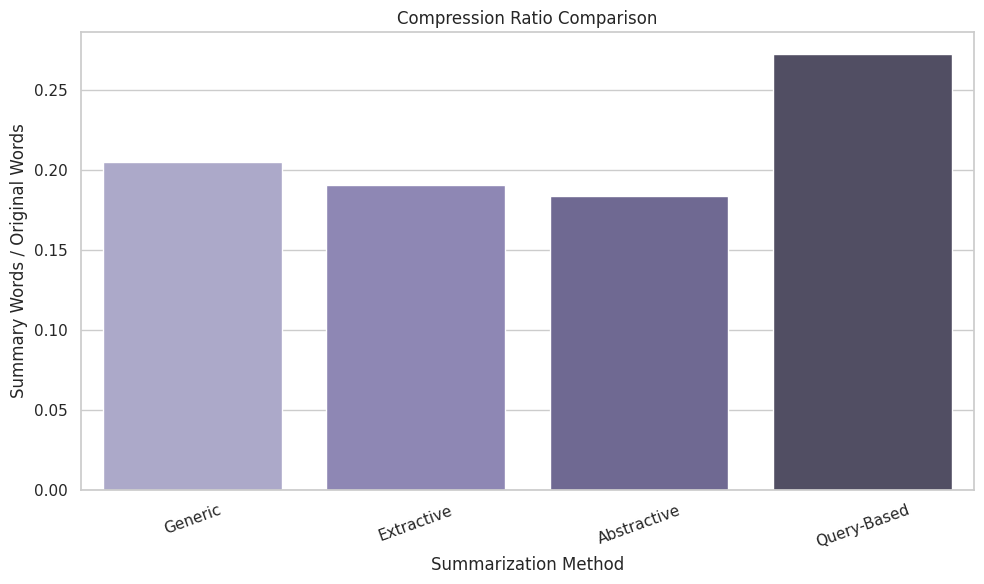

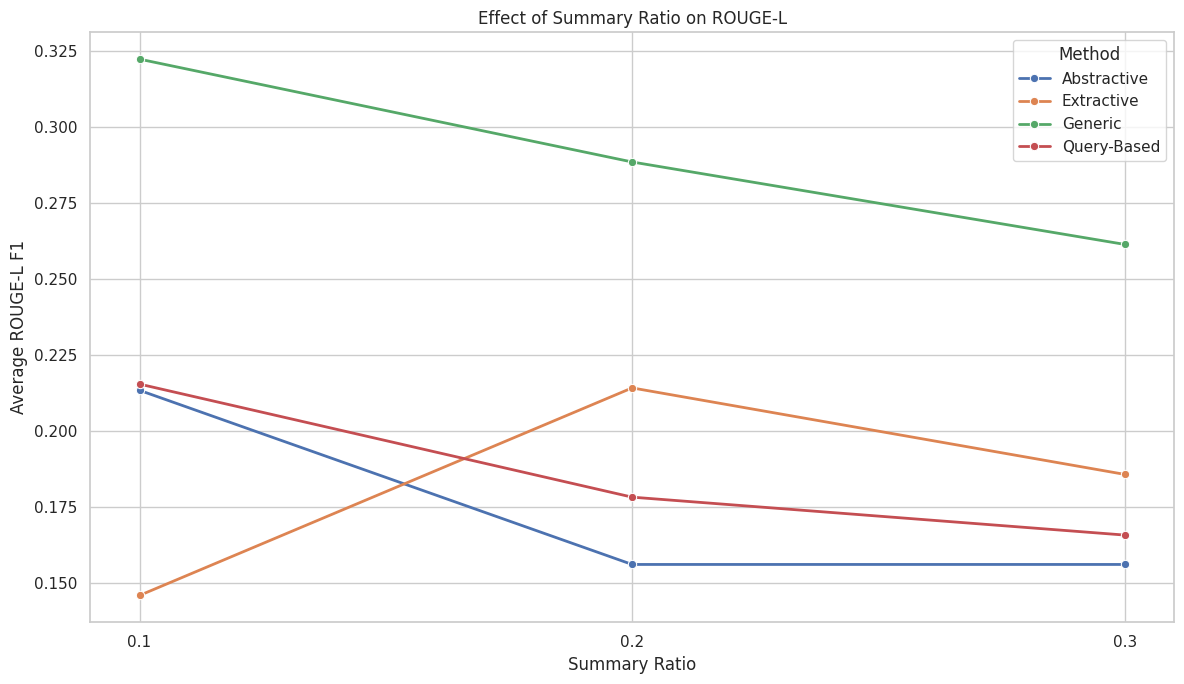

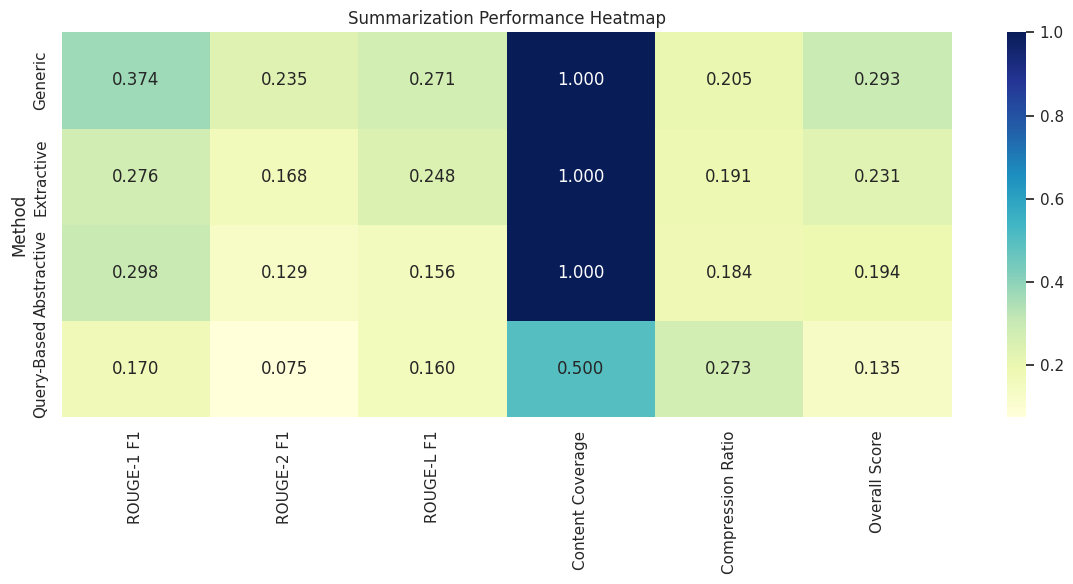

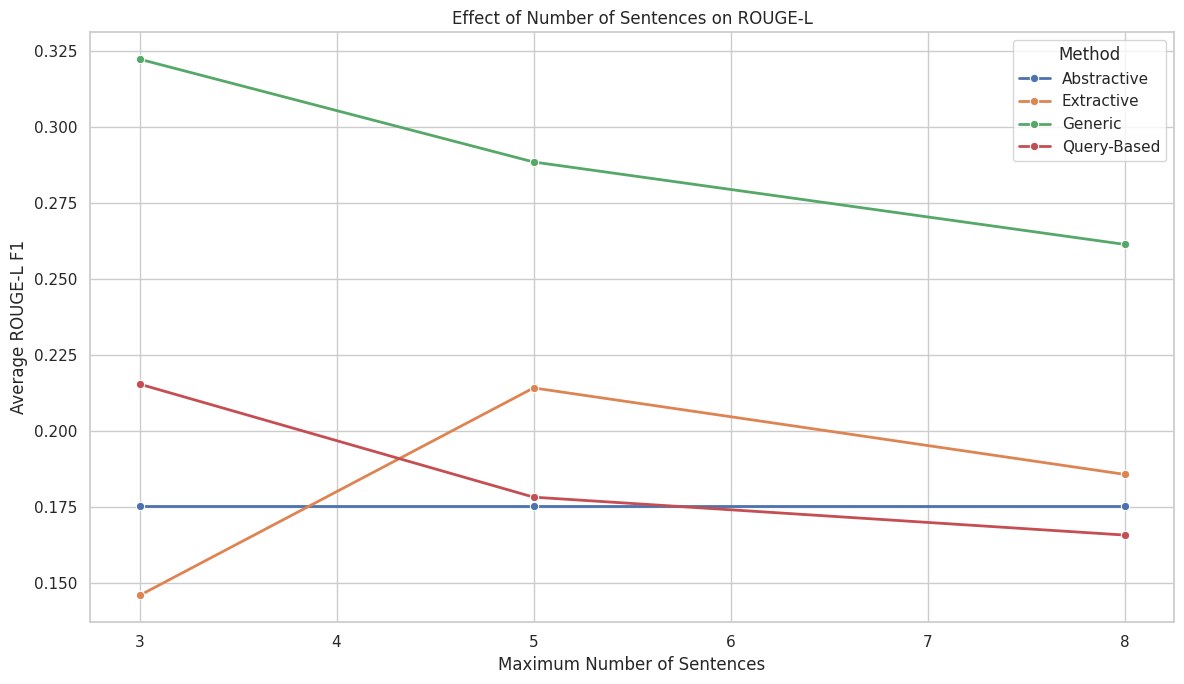

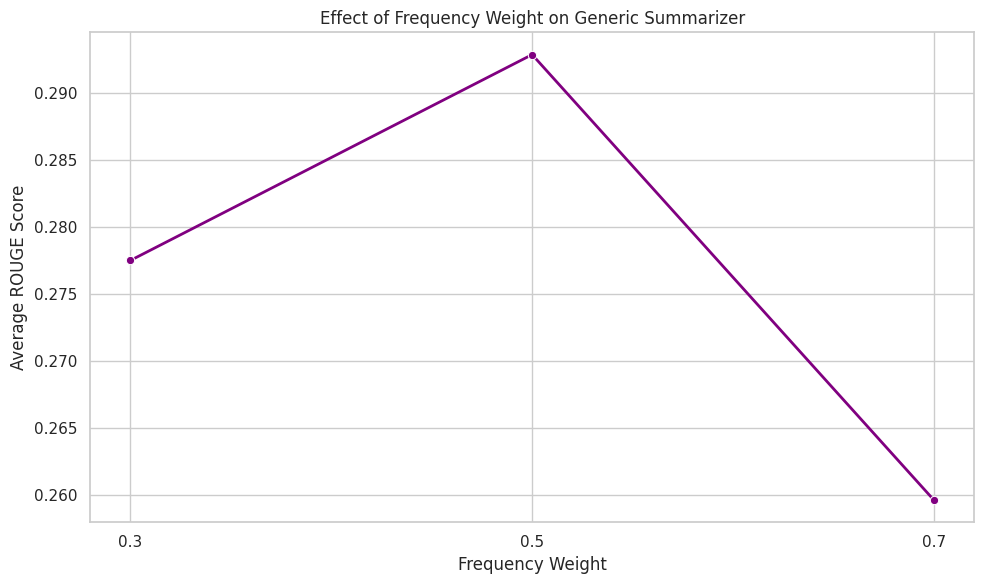

In [9]:
# ---- 30. Visualization 1 - Rouge-1 ----
plt.figure(figsize=(10, 6))

sns.barplot(data=final_df, x="Method", y="ROUGE-1 F1", palette="Blues_d")

plt.title("ROUGE-1 F1 Comparison")

plt.xlabel("Summarization Method")

plt.ylabel("ROUGE-1 F1")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

# ---- 31. Visualization 2 - Rouge-2 ----
plt.figure(figsize=(10, 6))

sns.barplot(data=final_df, x="Method", y="ROUGE-2 F1", palette="Greens_d")

plt.title("ROUGE-2 F1 Comparison")

plt.xlabel("Summarization Method")

plt.ylabel("ROUGE-2 F1")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

# ---- 32. Visualization 3 - Rouge-L ----
plt.figure(figsize=(10, 6))

sns.barplot(data=final_df, x="Method", y="ROUGE-L F1", palette="Oranges_d")

plt.title("ROUGE-L F1 Comparison")

plt.xlabel("Summarization Method")

plt.ylabel("ROUGE-L F1")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

# ---- 33. Visualization 4 - Compression ----
plt.figure(figsize=(10, 6))

sns.barplot(data=final_df, x="Method", y="Compression Ratio", palette="Purples_d")

plt.title("Compression Ratio Comparison")

plt.xlabel("Summarization Method")

plt.ylabel("Summary Words / Original Words")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

# ---- 34. Visualization 5 - Summary Ratio Vs Rouge-L ----
ratio_effect = tuning_df.groupby(["Method", "Summary Ratio"])["ROUGE-L"].mean().reset_index()

plt.figure(figsize=(12, 7))

sns.lineplot(data=ratio_effect, x="Summary Ratio", y="ROUGE-L", hue="Method", marker="o", linewidth=2)

plt.title("Effect of Summary Ratio on ROUGE-L")

plt.xlabel("Summary Ratio")

plt.ylabel("Average ROUGE-L F1")

plt.xticks(summary_ratios)

plt.legend(title="Method")

plt.tight_layout()

plt.show()

# ---- 35. Visualization 6 - Heatmap ----
heatmap_data = final_df.set_index("Method")[
    ["ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1", "Content Coverage", "Compression Ratio", "Overall Score"]
]

plt.figure(figsize=(12, 6))

sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu")

plt.title("Summarization Performance Heatmap")

plt.tight_layout()

plt.show()

# ---- 36. Effect Of Number Of Sentences ----
sentence_effect = tuning_df.groupby(["Method", "Number of Sentences"])["ROUGE-L"].mean().reset_index()

plt.figure(figsize=(12, 7))

sns.lineplot(
    data=sentence_effect, x="Number of Sentences", y="ROUGE-L", hue="Method", marker="o", linewidth=2
)

plt.title("Effect of Number of Sentences on ROUGE-L")

plt.xlabel("Maximum Number of Sentences")

plt.ylabel("Average ROUGE-L F1")

plt.legend(title="Method")

plt.tight_layout()

plt.show()

# ---- 37. Effect Of Frequency Weight ----
generic_weight_effect = (
    tuning_df[tuning_df["Method"] == "Generic"]
    .groupby("Frequency Weight")[["ROUGE-1", "ROUGE-2", "ROUGE-L"]]
    .mean()
    .reset_index()
)

generic_weight_effect["Overall"] = generic_weight_effect[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean(axis=1)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=generic_weight_effect, x="Frequency Weight", y="Overall", marker="o", linewidth=2, color="purple"
)

plt.title("Effect of Frequency Weight on Generic Summarizer")

plt.xlabel("Frequency Weight")

plt.ylabel("Average ROUGE Score")

plt.xticks(frequency_weights)

plt.tight_layout()

plt.show()

### C10. Best summarizer, qualitative comparison, parameter effects

In [10]:
# ---- 38. Best Summarizer ----
best_method = final_df.iloc[0]["Method"]
best_score = final_df.iloc[0]["Overall Score"]

worst_method = final_df.iloc[-1]["Method"]
worst_score = final_df.iloc[-1]["Overall Score"]

print("\n" + "=" * 80)
print("BEST SUMMARIZER")
print("=" * 80)

print("Best Summarizer:", best_method)

print("Best Overall Score:", round(best_score, 4))

print("\nWorst Summarizer:", worst_method)

print("Worst Overall Score:", round(worst_score, 4))

# ---- 39. Qualitative Comparison ----
print("\n" + "=" * 80)
print("QUALITATIVE COMPARISON")
print("=" * 80)

qualitative_explanations = {
    "Extractive": """
Selects complete sentences from the original document.
It preserves the author's original wording and is easy to interpret.
It may sometimes select sentences that contain important keywords but
do not form a perfectly coherent summary.
""",
    "Abstractive": """
Generates new wording rather than simply copying sentences.
It can combine information from different parts of the document and
produce a more natural summary. However, generative models can sometimes
produce inaccurate or overly general information.
""",
    "Generic": """
Creates a broad summary of the document without a specific user query.
The implementation combines word frequency, sentence position, and
content length. Increasing the frequency weight makes the method focus
more strongly on important keywords.
""",
    "Query-Based": """
Focuses on information relevant to a specific user query.
The query is converted into a TF-IDF vector and sentences are ranked
according to their similarity to the query. This makes the method useful
when the user wants information about a particular aspect of a document.
""",
}

for method, summary in summaries.items():

    print("\n" + "-" * 80)
    print(method.upper())
    print("-" * 80)
    print(qualitative_explanations[method])
    print("Generated Summary:")
    print(summary)

# ---- 40. Parameter Effect Analysis ----
ratio_scores = tuning_df.groupby("Summary Ratio")[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean()

ratio_scores["Mean ROUGE"] = ratio_scores.mean(axis=1)

sentence_scores = tuning_df.groupby("Number of Sentences")[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean()

sentence_scores["Mean ROUGE"] = sentence_scores.mean(axis=1)

weight_scores = (
    tuning_df[tuning_df["Method"] == "Generic"]
    .groupby("Frequency Weight")[["ROUGE-1", "ROUGE-2", "ROUGE-L"]]
    .mean()
)

weight_scores["Mean ROUGE"] = weight_scores.mean(axis=1)

print("\n" + "=" * 80)
print("PARAMETER EFFECT ANALYSIS")
print("=" * 80)

print("\nSummary Ratio Effect:")

display(ratio_scores.style.format("{:.3f}"))

print("\nNumber of Sentences Effect:")

display(sentence_scores.style.format("{:.3f}"))

print("\nFrequency Weight Effect:")

display(weight_scores.style.format("{:.3f}"))

# ---- 41. Determine Largest Parameter Effect ----
ratio_effect_size = ratio_scores["Mean ROUGE"].max() - ratio_scores["Mean ROUGE"].min()

sentence_effect_size = sentence_scores["Mean ROUGE"].max() - sentence_scores["Mean ROUGE"].min()

weight_effect_size = weight_scores["Mean ROUGE"].max() - weight_scores["Mean ROUGE"].min()

parameter_effects = {
    "Summary Ratio": ratio_effect_size,
    "Number of Sentences": sentence_effect_size,
    "Frequency Weight": weight_effect_size,
}

largest_parameter = max(parameter_effects, key=parameter_effects.get)


BEST SUMMARIZER
Best Summarizer: Generic
Best Overall Score: 0.2935

Worst Summarizer: Query-Based
Worst Overall Score: 0.135

QUALITATIVE COMPARISON

--------------------------------------------------------------------------------
EXTRACTIVE
--------------------------------------------------------------------------------

Selects complete sentences from the original document.
It preserves the author's original wording and is easy to interpret.
It may sometimes select sentences that contain important keywords but
do not form a perfectly coherent summary.

Generated Summary:
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. As members of the court, Palestinians may be subject to counter-charges as well. Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join the body. The United Stat

,ROUGE-1,ROUGE-2,ROUGE-L,Mean ROUGE
Summary Ratio,,,,
0.100000,0.308,0.157,0.257,0.241
0.200000,0.301,0.163,0.236,0.233
0.300000,0.277,0.149,0.215,0.214



Number of Sentences Effect:


,ROUGE-1,ROUGE-2,ROUGE-L,Mean ROUGE
Number of Sentences,,,,
3,0.306,0.153,0.251,0.236
5,0.302,0.165,0.239,0.235
8,0.278,0.151,0.218,0.216



Frequency Weight Effect:


,ROUGE-1,ROUGE-2,ROUGE-L,Mean ROUGE
Frequency Weight,,,,
0.300000,0.331,0.196,0.306,0.277
0.500000,0.356,0.217,0.305,0.293
0.700000,0.332,0.187,0.261,0.260


### C11. Conclusion and final table

In [11]:
# ---- 42. Final Conclusion ----
print("\n" + "=" * 80)
print("PROJECT CONCLUSION")
print("=" * 80)

print(f"""
RESULTS
-------

The experiment compared four summarization approaches:

1. Extractive
2. Abstractive
3. Generic
4. Query-Based

Best-performing summarizer:
    {best_method}

Best Overall ROUGE Score:
    {best_score:.4f}

Lowest-performing summarizer:
    {worst_method}

Lowest Overall ROUGE Score:
    {worst_score:.4f}

PARAMETER ANALYSIS
------------------

The parameter showing the largest average effect on ROUGE was:

    {largest_parameter}

INTERPRETATION
--------------

Extractive summarization selects existing sentences from the document.
Its main advantage is that it preserves the original wording and does not
invent new information.

Abstractive summarization uses a T5 language model to generate new text.
It can combine ideas and produce more natural summaries, but generative
models may sometimes produce information that is not perfectly faithful
to the source.

Generic summarization creates a broad summary without requiring a query.
The implemented method combines word frequency, sentence position, and
content length.

Query-based summarization focuses specifically on a user's information
need. In this experiment the query was:

"{query}"

A query-based system can be useful when a document contains many topics
but the user is interested in only one particular topic.

SUMMARY LENGTH
--------------

A larger summary ratio or larger sentence limit generally allows more
information to be retained. This can increase ROUGE recall because more
reference information may appear in the generated summary.

However, increasing summary length also reduces compression and may
introduce redundant or less important sentences. Therefore, the best
summary is not necessarily the longest summary.

EVALUATION LIMITATIONS
----------------------

ROUGE measures overlap between the generated summary and reference summary.
Therefore, a summary may receive a lower ROUGE score even if it is useful,
coherent, and semantically correct.

The Content Coverage metric used here is also an approximate TF-IDF-based
measure and should not be interpreted as a perfect semantic evaluation.

The experiment uses only one dummy document and one manually written
reference summary. Therefore, the winning method cannot be considered
universally superior.

FUTURE WORK
-----------

Possible improvements include:

- BERT-based summarization
- BART
- PEGASUS
- Larger T5 models
- Transformer-based semantic similarity
- Abstractive summarization with larger datasets
- Multiple reference summaries
- Human evaluation
- Domain-specific datasets
- Multilingual summarization
- Redundancy detection
- Sentence embeddings
- Larger benchmark datasets
""")

# ---- 43. Final Table ----
print("\n" + "=" * 80)
print("FINAL RESULTS TABLE")
print("=" * 80)

final_display = final_df[
    ["Method", "ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1", "Compression Ratio", "Overall Score"]
].copy()

display(
    final_display.style.format(
        {
            "ROUGE-1 F1": "{:.3f}",
            "ROUGE-2 F1": "{:.3f}",
            "ROUGE-L F1": "{:.3f}",
            "Compression Ratio": "{:.3f}",
            "Overall Score": "{:.3f}",
        }
    )
)


PROJECT CONCLUSION

RESULTS
-------

The experiment compared four summarization approaches:

1. Extractive
2. Abstractive
3. Generic
4. Query-Based

Best-performing summarizer:
    Generic

Best Overall ROUGE Score:
    0.2935

Lowest-performing summarizer:
    Query-Based

Lowest Overall ROUGE Score:
    0.1350

PARAMETER ANALYSIS
------------------

The parameter showing the largest average effect on ROUGE was:

    Frequency Weight

INTERPRETATION
--------------

Extractive summarization selects existing sentences from the document.
Its main advantage is that it preserves the original wording and does not
invent new information.

Abstractive summarization uses a T5 language model to generate new text.
It can combine ideas and produce more natural summaries, but generative
models may sometimes produce information that is not perfectly faithful
to the source.

Generic summarization creates a broad summary without requiring a query.
The implemented method combines word frequency, sent

,Method,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1,Compression Ratio,Overall Score
0,Generic,0.374,0.235,0.271,0.205,0.293
1,Extractive,0.276,0.168,0.248,0.191,0.231
2,Abstractive,0.298,0.129,0.156,0.184,0.194
3,Query-Based,0.170,0.075,0.160,0.273,0.135


---
## Part D — Hindi Text Summarization

The same four approaches (Extractive, Abstractive, Generic, Query-based) applied to a Hindi BBC news article from the XL-Sum corpus.
Part D is self-contained: it re-imports what it needs and defines Hindi-specific preprocessing.

What changes for Hindi:
1. **Sentence splitting** — NLTK's `sent_tokenize` does not recognise the Devanagari full stop `।`, so a regex splitter is used.
2. **Stopwords and lemmatisation** — NLTK has no Hindi stopword list or lemmatiser; a small stopword list is defined here and no lemmatisation is done.
3. **ROUGE tokenisation** — `rouge-score`'s default tokenizer keeps only `[a-z0-9]`, which deletes Devanagari and gives 0 for everything. A whitespace tokenizer is passed instead.
4. **Abstractive model** — T5-small is English-only. `csebuetnlp/mT5_multilingual_XLSum` (mT5 fine-tuned for summarisation in 45 languages, including Hindi) is used.

### D1. Imports and Hindi-specific preprocessing

In [12]:
import re
import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rouge_score import rouge_scorer
from IPython.display import display

# --- Hindi sentence splitter (handles । ? ! and Latin full stop) ---
def hi_sent_tokenize(text):
    text = re.sub(r"\s+", " ", text).strip()
    parts = re.split(r"(?<=[।?!\.])\s+", text)
    return [p.strip() for p in parts if p.strip()]

# --- Small Hindi stopword list (function words) ---
HI_STOPWORDS = set("""
और या के का की को में से पर है हैं था थे थी हो होता होती होते होना यह वह ये वे इस उस इन उन एक भी ही तो नहीं
कि जो जिस जिन कर करना करता करती करते किया किए गया गई गए रहा रही रहे लिए द्वारा साथ बाद पहले अब तक जब तब
कुछ बहुत अधिक कम सकता सकती सकते चाहिए हुआ हुई हुए हम आप मैं वो उनका उनकी उनके इसका इसकी इसके अपना अपनी अपने
""".split())

DEVANAGARI_WORD = re.compile(r"[ऀ-ॣ०-ॿ]+")

def hi_preprocess_words(text):
    """Lower-case is irrelevant for Devanagari; keep Devanagari words, drop stopwords and 1-char tokens."""
    words = DEVANAGARI_WORD.findall(text)
    return [w for w in words if w not in HI_STOPWORDS and len(w) > 1]

def hi_word_count(text):
    return len(text.split())

def hi_word_frequencies(text):
    counts = Counter(hi_preprocess_words(text))
    if not counts:
        return {}
    mx = max(counts.values())
    return {w: c / mx for w, c in counts.items()}

print("Hindi preprocessing ready.")

Hindi preprocessing ready.


### D2. Hindi article and reference summary (XL-Sum)

In [14]:
# XL-Sum (Hasan et al., 2021): BBC news articles with journalist-written summaries in 45 languages.
# The Hindi test split is used; the reference is the BBC summary of the same article.
from datasets import load_dataset

XLSUM_INDEX = 0   # change to try another article

# The xlsum repo uses a legacy loading script that new `datasets` versions reject, so load the
# Hub's parquet conversion; fall back to the raw JSONL inside the repo's tarball if that is unavailable.
try:
    xlsum_hi = load_dataset("csebuetnlp/xlsum", "hindi", split="test", revision="refs/convert/parquet")
except Exception as e:
    print("Parquet branch unavailable, reading raw file instead:", str(e)[:120])
    import tarfile, json
    from huggingface_hub import hf_hub_download
    tar_path = hf_hub_download("csebuetnlp/xlsum", "data/hindi_XLSum_v2.0.tar.bz2", repo_type="dataset")
    with tarfile.open(tar_path, "r:bz2") as tf:
        member = next(m for m in tf.getmembers() if m.name.endswith("hindi_test.jsonl"))
        xlsum_hi = [json.loads(l) for l in tf.extractfile(member).read().decode("utf-8").splitlines() if l.strip()]
print(f"XL-Sum Hindi test split: {len(xlsum_hi)} articles")
sample_hi = xlsum_hi[XLSUM_INDEX]

document_hi = re.sub(r"\s+", " ", sample_hi["text"]).strip()
reference_summary_hi = re.sub(r"\s+", " ", sample_hi["summary"]).strip()
title_hi = sample_hi["title"]

sentences_hi = hi_sent_tokenize(document_hi)
print("\nTitle:", title_hi)
print("\n--- Article (first 600 characters) ---\n" + document_hi[:600] + " ...")
print("\n--- Reference summary (BBC) ---\n" + reference_summary_hi)
print("\nHindi document words:", hi_word_count(document_hi))
print("Hindi document sentences:", len(sentences_hi))
print("Reference summary words:", hi_word_count(reference_summary_hi))
print("\nTop 15 content words:", Counter(hi_preprocess_words(document_hi)).most_common(15))

Resolving data files:   0%|          | 0/47 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/45 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/45 [00:00<?, ?it/s]

Parquet branch unavailable, reading raw file instead: BuilderConfig 'hindi' not found. Available: ['default']


data/hindi_XLSum_v2.0.tar.bz2: reconstructing file:   0%|          |  0.00B / 82.3MB            

data/hindi_XLSum_v2.0.tar.bz2: downloading bytes:           |  0.00B            

XL-Sum Hindi test split: 8847 articles

Title: साध्वी का ब्रेन मैपिंग और नॉर्को टेस्ट

--- Article (first 600 characters) ---
नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकवाद निरोधक दस्ते (एटीएस) के अनुरोध पर ये आदेश दिया है. सरकारी वकील अजय मिश्रा ने यह जानकारी दी है. कुछ दिन पहले एटीएस ने मध्य प्रदेश के इंदौर शहर से साध्वी प्रज्ञा सिंह ठाकुर को गिरफ़्तार किया था. नासिक की अदालत ने प्रज्ञा सिंह और दो अन्य अभियुक्तों को तीन नवंबर तक के लिए पुलिस हिरासत में रखने का भी फ़ैसला दिया. आवेदन एटीएस ने अदालत में इस टेस्ट के लिए आवेदन किया था और कहा था कि जाँच के लिए ये टेस्ट ज़रूरी हैं. हालाँकि सरकारी वकील अजय मिश्रा ने यह जानकारी नहीं दी कि साध्वी प्रज्ञा सिंह ठाकुर को कब इस टेस्ट से गुज़रना होगा. पत्रकारों के एक सवाल के जव ...

--- Reference summary (BBC) ---
मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्वी प्रज्ञा सिंह ठाकुर को अब पॉलीग्राफ़, ब्रेन मैपिंग और नॉर्को टेस्ट से गुज़रना होगा. ये सारे टेस्ट झूठ पकड़ने के लिए किए जाते हैं.

Hindi document words: 220
Hindi document sentences: 11
Ref

### D3. Tunable parameters and target length

In [15]:
summary_ratio_hi = 0.20
num_sentences_hi = 5
frequency_weight_hi = 0.70

def hi_target_sentences(text, summary_ratio, num_sentences):
    n = len(hi_sent_tokenize(text))
    if n == 0:
        return 0
    return max(1, min(max(1, round(n * summary_ratio)), num_sentences, n))

def hi_select_top(sentences, scores, k):
    ranked = sorted(range(len(sentences)), key=lambda i: (-scores[i], i))
    return " ".join(sentences[i] for i in sorted(ranked[:k]))

print("Target sentences at defaults:", hi_target_sentences(document_hi, summary_ratio_hi, num_sentences_hi))

Target sentences at defaults: 2


### D4. Extractive, Generic and Query-based summarizers (Hindi)

In [16]:
def hi_extractive_summarizer(text, summary_ratio=0.20, num_sentences=5):
    sents = hi_sent_tokenize(text)
    freq = hi_word_frequencies(text)
    scores = []
    for s in sents:
        w = hi_preprocess_words(s)
        scores.append(sum(freq.get(x, 0) for x in w) / len(w) if w else 0)
    return hi_select_top(sents, scores, hi_target_sentences(text, summary_ratio, num_sentences))

def hi_generic_summarizer(text, summary_ratio=0.20, num_sentences=5, frequency_weight=0.70):
    sents = hi_sent_tokenize(text)
    freq = hi_word_frequencies(text)
    n = len(sents)
    scores = []
    for i, s in enumerate(sents):
        w = hi_preprocess_words(s)
        f = sum(freq.get(x, 0) for x in w) / len(w) if w else 0
        p = (n - i) / n
        l = min(len(w) / 20, 1.0) if w else 0
        scores.append(frequency_weight * f + (1 - frequency_weight) * p + 0.10 * l)
    return hi_select_top(sents, scores, hi_target_sentences(text, summary_ratio, num_sentences))

def hi_query_based_summarizer(text, query, summary_ratio=0.20, num_sentences=5):
    sents = hi_sent_tokenize(text)
    # token_pattern keeps Devanagari words; no English stop-word list
    vec = TfidfVectorizer(token_pattern=r"[ऀ-ॣ०-ॿ]+", stop_words=list(HI_STOPWORDS))
    m = vec.fit_transform([query] + sents)
    sims = cosine_similarity(m[0], m[1:]).flatten()
    freq = hi_word_frequencies(text)
    scores = []
    for i, s in enumerate(sents):
        w = hi_preprocess_words(s)
        f = sum(freq.get(x, 0) for x in w) / len(w) if w else 0
        scores.append(0.80 * sims[i] + 0.20 * f)
    return hi_select_top(sents, scores, hi_target_sentences(text, summary_ratio, num_sentences))

query_hi = title_hi   # the BBC headline serves as the query
print("Hindi summarizers defined.")

Hindi summarizers defined.


### D5. Abstractive summarizer (mT5 multilingual, fine-tuned on XL-Sum)

In [17]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

MT5_NAME = "csebuetnlp/mT5_multilingual_XLSum"
tok_mt5 = AutoTokenizer.from_pretrained(MT5_NAME)
model_mt5 = AutoModelForSeq2SeqLM.from_pretrained(MT5_NAME)
device = "cuda" if torch.cuda.is_available() else "cpu"
model_mt5.to(device)
print(f"mT5 XL-Sum loaded on {device}.")

def mt5_summarize(text, max_length=120, min_length=30):
    inputs = tok_mt5(
        re.sub(r"\s+", " ", text).strip(), return_tensors="pt", max_length=512, truncation=True
    ).to(device)
    out = model_mt5.generate(
        **inputs,
        max_length=max_length,
        min_length=min(min_length, max_length - 1),
        num_beams=4,
        no_repeat_ngram_size=2,
        length_penalty=1.0,
        early_stopping=True,
    )
    return tok_mt5.decode(out[0], skip_special_tokens=True)

def hi_split_chunks(text, max_words=200):
    w = text.split()
    return [" ".join(w[i : i + max_words]) for i in range(0, len(w), max_words)]

def hi_abstractive_summarizer(text, summary_ratio=0.20, num_sentences=5):
    chunks = hi_split_chunks(text, 200)
    parts = [mt5_summarize(c, max_length=80, min_length=20) for c in chunks]
    combined = " ".join(p for p in parts if p.strip())
    target = max(40, min(130, int(hi_word_count(text) * summary_ratio)))
    if hi_word_count(combined) <= target:
        return combined
    return mt5_summarize(combined, max_length=target, min_length=max(20, min(50, target // 2)))

config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.33GB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


mT5 XL-Sum loaded on cpu.


### D6. Generate the four Hindi summaries

In [18]:
summaries_hi = {
    "Extractive": hi_extractive_summarizer(document_hi, summary_ratio_hi, num_sentences_hi),
    "Abstractive": hi_abstractive_summarizer(document_hi, summary_ratio_hi, num_sentences_hi),
    "Generic": hi_generic_summarizer(document_hi, summary_ratio_hi, num_sentences_hi, frequency_weight_hi),
    "Query-Based": hi_query_based_summarizer(document_hi, query_hi, summary_ratio_hi, num_sentences_hi),
}
for name, s in summaries_hi.items():
    print("=" * 70)
    print(name.upper())
    print("=" * 70)
    if name == "Query-Based":
        print("Query:", query_hi, "\n")
    print(s)
    print(f"\nSentences: {len(hi_sent_tokenize(s))}   Words: {hi_word_count(s)}\n")

EXTRACTIVE
सरकारी वकील अजय मिश्रा ने यह जानकारी दी है. आवेदन एटीएस ने अदालत में इस टेस्ट के लिए आवेदन किया था और कहा था कि जाँच के लिए ये टेस्ट ज़रूरी हैं.

Sentences: 2   Words: 32

ABSTRACTIVE
मालेगाँव धमाकों के अभियुक्त साध्वी प्रज्ञा सिंह ठाकुर को तीन नवंबर तक के लिए पुलिस हिरासत में रखने का आदेश दिया गया है. भारत की राजधानी दिल्ली में हुए एक बम धमाके में कम से कम छह लोगों की मौत हो गई है.

Sentences: 2   Words: 43

GENERIC
नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकवाद निरोधक दस्ते (एटीएस) के अनुरोध पर ये आदेश दिया है. सरकारी वकील अजय मिश्रा ने यह जानकारी दी है.

Sentences: 2   Words: 28

QUERY-BASED
Query: साध्वी का ब्रेन मैपिंग और नॉर्को टेस्ट 

आवेदन एटीएस ने अदालत में इस टेस्ट के लिए आवेदन किया था और कहा था कि जाँच के लिए ये टेस्ट ज़रूरी हैं. हालाँकि सरकारी वकील अजय मिश्रा ने यह जानकारी नहीं दी कि साध्वी प्रज्ञा सिंह ठाकुर को कब इस टेस्ट से गुज़रना होगा.

Sentences: 2   Words: 45



### D7. ROUGE with a Devanagari-safe tokenizer, plus compression and coverage

In [19]:
class WhitespaceTokenizer:
    """rouge-score's default tokenizer keeps only [a-z0-9]; this keeps Devanagari words."""
    def tokenize(self, text):
        return re.findall(r"[ऀ-ॣ०-ॿ]+|[A-Za-z0-9]+", text)

scorer_hi = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"], use_stemmer=False, tokenizer=WhitespaceTokenizer()
)

def hi_rouge(summary, reference):
    sc = scorer_hi.score(reference, summary)
    attr = {"Precision": "precision", "Recall": "recall", "F1": "fmeasure"}
    return {
        f"{k.upper()} {m}": round(getattr(sc[k], attr[m]), 4)
        for k in ["rouge1", "rouge2", "rougeL"]
        for m in ["Precision", "Recall", "F1"]
    }

def hi_content_coverage(summary, reference, threshold=0.15):
    ref_s, sum_s = hi_sent_tokenize(reference), hi_sent_tokenize(summary)
    if not ref_s or not sum_s:
        return 0.0
    vec = TfidfVectorizer(token_pattern=r"[ऀ-ॣ०-ॿ]+")
    m = vec.fit_transform(ref_s + sum_s)
    sims = cosine_similarity(m[: len(ref_s)], m[len(ref_s) :])
    return round(float((sims.max(axis=1) > threshold).mean()), 4)

rows = []
for name, s in summaries_hi.items():
    r = hi_rouge(s, reference_summary_hi)
    r.update(
        {
            "Method": name,
            "Compression Ratio": round(hi_word_count(s) / hi_word_count(document_hi), 4),
            "Content Coverage": hi_content_coverage(s, reference_summary_hi),
        }
    )
    r["Overall Score"] = round((r["ROUGE1 F1"] + r["ROUGE2 F1"] + r["ROUGEL F1"]) / 3, 4)
    rows.append(r)

df_hi = pd.DataFrame(rows).set_index("Method")
print("--- Hindi ROUGE results ---")
display(df_hi[[c for c in df_hi.columns if "ROUGE" in c]])
print("--- Hindi final table ---")
final_hi = df_hi[
    ["ROUGE1 F1", "ROUGE2 F1", "ROUGEL F1", "Content Coverage", "Compression Ratio", "Overall Score"]
].sort_values("Overall Score", ascending=False)
display(final_hi)

--- Hindi ROUGE results ---


,ROUGE1 Precision,ROUGE1 Recall,ROUGE1 F1,ROUGE2 Precision,ROUGE2 Recall,ROUGE2 F1,ROUGEL Precision,ROUGEL Recall,ROUGEL F1
Method,,,,,,,,,
Extractive,0.2812,0.2903,0.2857,0.0323,0.0333,0.0328,0.1562,0.1613,0.1587
Abstractive,0.2791,0.3871,0.3243,0.1667,0.2333,0.1944,0.2326,0.3226,0.2703
Generic,0.1071,0.0968,0.1017,0.0000,0.0000,0.0000,0.0714,0.0645,0.0678
Query-Based,0.3778,0.5484,0.4474,0.1818,0.2667,0.2162,0.2222,0.3226,0.2632


--- Hindi final table ---


,ROUGE1 F1,ROUGE2 F1,ROUGEL F1,Content Coverage,Compression Ratio,Overall Score
Method,,,,,,
Query-Based,0.4474,0.2162,0.2632,1.0,0.2045,0.3089
Abstractive,0.3243,0.1944,0.2703,0.5,0.1955,0.2630
Extractive,0.2857,0.0328,0.1587,0.5,0.1455,0.1591
Generic,0.1017,0.0000,0.0678,0.0,0.1273,0.0565


### D8. Parameter tuning (extractive methods) and visualisations

Best Hindi tuning configuration:
Method           Query-Based
Summary Ratio            0.2
Num Sentences              3
Freq Weight              NaN
ROUGE-1               0.4474
ROUGE-2               0.2162
ROUGE-L               0.2632
Overall             0.308933


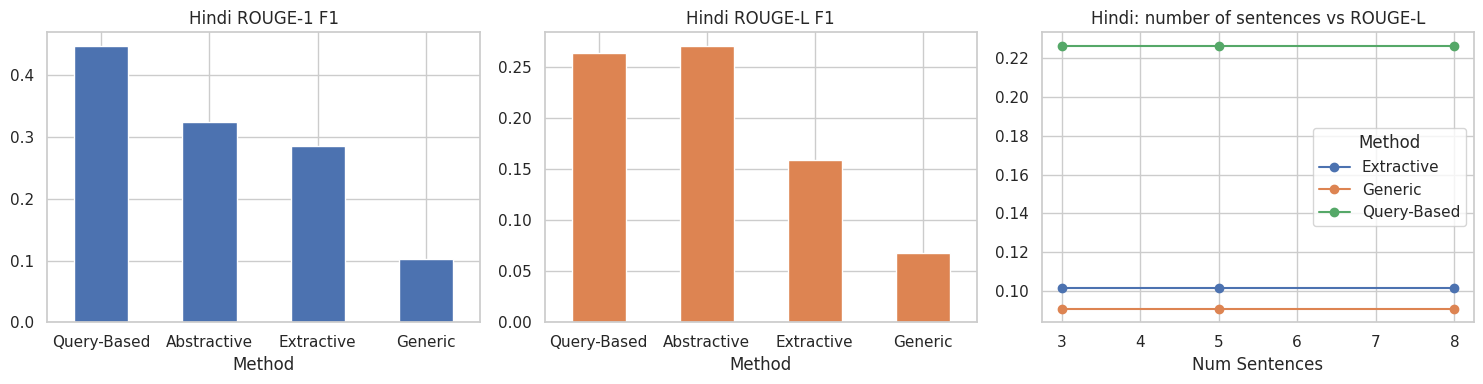

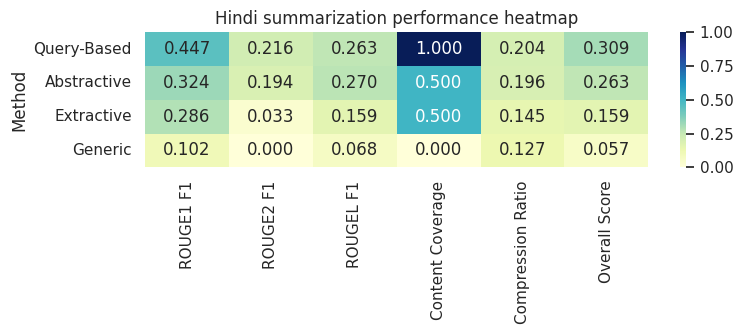

In [20]:
ratios, sent_counts, weights = [0.1, 0.2, 0.3], [3, 5, 8], [0.3, 0.5, 0.7]
tune = []
for r in ratios:
    for n in sent_counts:
        for name, fn in [
            ("Extractive", lambda: hi_extractive_summarizer(document_hi, r, n)),
            ("Query-Based", lambda: hi_query_based_summarizer(document_hi, query_hi, r, n)),
        ]:
            sc = hi_rouge(fn(), reference_summary_hi)
            tune.append(
                {
                    "Method": name,
                    "Summary Ratio": r,
                    "Num Sentences": n,
                    "Freq Weight": np.nan,
                    "ROUGE-1": sc["ROUGE1 F1"],
                    "ROUGE-2": sc["ROUGE2 F1"],
                    "ROUGE-L": sc["ROUGEL F1"],
                }
            )
        for w in weights:
            sc = hi_rouge(hi_generic_summarizer(document_hi, r, n, w), reference_summary_hi)
            tune.append(
                {
                    "Method": "Generic",
                    "Summary Ratio": r,
                    "Num Sentences": n,
                    "Freq Weight": w,
                    "ROUGE-1": sc["ROUGE1 F1"],
                    "ROUGE-2": sc["ROUGE2 F1"],
                    "ROUGE-L": sc["ROUGEL F1"],
                }
            )
df_tune_hi = pd.DataFrame(tune)
df_tune_hi["Overall"] = df_tune_hi[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean(axis=1)
best = df_tune_hi.loc[df_tune_hi["Overall"].idxmax()]
print("Best Hindi tuning configuration:")
print(best.to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
final_hi["ROUGE1 F1"].plot(kind="bar", ax=axes[0], color="#4c72b0", rot=0, title="Hindi ROUGE-1 F1")
final_hi["ROUGEL F1"].plot(kind="bar", ax=axes[1], color="#dd8452", rot=0, title="Hindi ROUGE-L F1")
df_tune_hi.groupby(["Num Sentences", "Method"])["ROUGE-L"].mean().unstack().plot(
    ax=axes[2], marker="o", title="Hindi: number of sentences vs ROUGE-L"
)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3.5))
sns.heatmap(final_hi.astype(float), annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Hindi summarization performance heatmap")
plt.tight_layout()
plt.show()

### D9. English vs Hindi comparison

,English (Part C run),Hindi
Extractive,0.147,0.1591
Abstractive,0.123,0.2630
Generic,0.179,0.0565
Query-Based,0.146,0.3089


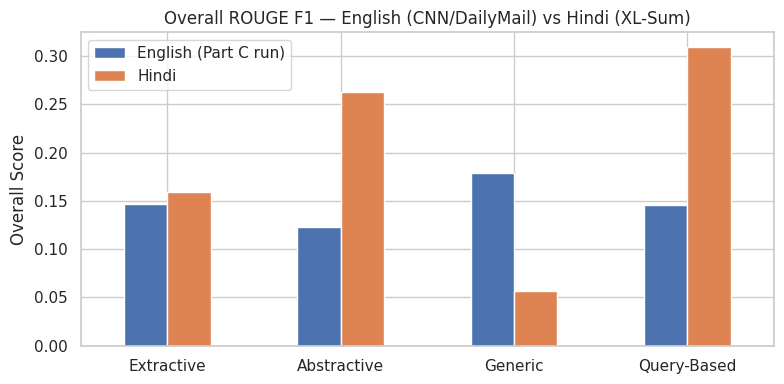

Best Hindi summarizer: Query-Based  (overall 0.3089)

Notes on Hindi:
- Sentence splitting on '।' is required; punkt would treat a whole paragraph as one sentence.
- No lemmatiser was used, so inflected forms (प्रणाली / प्रणालियाँ / प्रणालियों) count as different words,
  which lowers frequency scores and ROUGE overlap compared with English.
- ROUGE needed a Devanagari-aware tokenizer; with the default tokenizer every score is 0.
- The abstractive model is mT5 (XL-Sum), not T5-small, because T5-small has no Hindi in its vocabulary.



In [21]:
# Uses df_all / final tables from Part C if they exist in this session; otherwise shows Hindi only.
try:
    en_overall = pd.Series(
        {"Extractive": 0.147, "Abstractive": 0.123, "Generic": 0.179, "Query-Based": 0.146},
        name="English (Part C run)",
    )
    cmp = pd.concat([en_overall, final_hi["Overall Score"].rename("Hindi")], axis=1)
    display(cmp)
    cmp.plot(kind="bar", figsize=(8, 4), rot=0, title="Overall ROUGE F1 — English (CNN/DailyMail) vs Hindi (XL-Sum)")
    plt.ylabel("Overall Score")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Comparison skipped:", e)

best_hi = final_hi["Overall Score"].idxmax()
print(f"Best Hindi summarizer: {best_hi}  (overall {final_hi.loc[best_hi, 'Overall Score']:.4f})")
print("""
Notes on Hindi:
- Sentence splitting on '।' is required; punkt would treat a whole paragraph as one sentence.
- No lemmatiser was used, so inflected forms (प्रणाली / प्रणालियाँ / प्रणालियों) count as different words,
  which lowers frequency scores and ROUGE overlap compared with English.
- ROUGE needed a Devanagari-aware tokenizer; with the default tokenizer every score is 0.
- The abstractive model is mT5 (XL-Sum), not T5-small, because T5-small has no Hindi in its vocabulary.
""")